In [23]:
import warnings

warnings.filterwarnings(
    "ignore",
    message="IProgress not found",
    category=UserWarning
)

In [24]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import optuna
import pacmap
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

from pyDRMetrics.pyDRMetrics import DRMetrics

from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

In [25]:
def calcular_metricas_reducao(X, Z):

    dr_metrics = DRMetrics(X, Z)

    q_local = dr_metrics.Qlocal
    auc_qnn = dr_metrics.AUC

    return q_local, auc_qnn


def calcular_score_reducao(X, Z):

    q_local, auc_qnn = calcular_metricas_reducao(X, Z)

    score = 0.5 * q_local + 0.5 * auc_qnn

    return score, q_local, auc_qnn


def calcular_metricas_clustering(Z, labels):

    n_clusters = len(np.unique(labels))

    if n_clusters < 2 or n_clusters >= len(labels):
        raise ValueError("Número inválido de clusters.")

    sil_score = silhouette_score(Z, labels)

    ch_score = calinski_harabasz_score(Z, labels)

    ch_score_norm = ch_score / (ch_score + 1000)

    return sil_score, ch_score, ch_score_norm


def calcular_score_clustering(Z, labels):

    sil_score, ch_score, ch_score_norm = (
        calcular_metricas_clustering(Z, labels)
    )

    score = 0.5 * sil_score + 0.5 * ch_score_norm

    return score, sil_score, ch_score, ch_score_norm

## Importando as bases de dados

In [26]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import optuna
import pacmap
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

from pyDRMetrics.pyDRMetrics import DRMetrics

from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)


# ============================================================
# Diretórios
# ============================================================

PROJECT_DIR = Path.cwd().parent

DATA_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR = PROJECT_DIR / "results"

OPTUNA_DIR = RESULTS_DIR / "optuna"
EMBEDDINGS_DIR = RESULTS_DIR / "embeddings"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"

for directory in [
    OPTUNA_DIR,
    EMBEDDINGS_DIR,
    METRICS_DIR,
    FIGURES_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)


# ============================================================
# Carregamento da base
# ============================================================

df = pd.read_csv(
    DATA_DIR / "mad_datasets" / "VST_MAD_3000.csv",
    index_col=0
)

clinical_final = pd.read_csv(
    DATA_DIR / "clinical_final.csv",
    index_col=0
)

# Mantém apenas a coluna de subtipo
clinical_final = clinical_final[["SUBTYPE"]]

# Alinha a tabela clínica à matriz de expressão
clinical_final = clinical_final.loc[df.index]

# Verificações
assert df.index.equals(clinical_final.index), (
    "Os índices da matriz de expressão e da tabela clínica não coincidem."
)

assert not df.isnull().values.any(), (
    "A matriz de expressão contém valores ausentes."
)

assert not clinical_final["SUBTYPE"].isnull().any(), (
    "A tabela clínica contém subtipos ausentes."
)

X_data = df.values
y_true = clinical_final["SUBTYPE"].values

print(f"Número de amostras: {X_data.shape[0]}")
print(f"Número de genes: {X_data.shape[1]}")
print(f"Número de subtipos clínicos: {clinical_final['SUBTYPE'].nunique()}")

print("\nDistribuição dos subtipos:")
print(clinical_final["SUBTYPE"].value_counts())

Número de amostras: 970
Número de genes: 3000
Número de subtipos clínicos: 5

Distribuição dos subtipos:
SUBTYPE
BRCA_LumA      494
BRCA_LumB      193
BRCA_Basal     171
BRCA_Her2       77
BRCA_Normal     35
Name: count, dtype: int64


In [27]:
print("Embeddings:")
for arquivo in EMBEDDINGS_DIR.glob("*"):
    print(arquivo.name)

print("\nMetrics:")
for arquivo in METRICS_DIR.glob("*"):
    print(arquivo.name)

print("\nOptuna:")
for arquivo in OPTUNA_DIR.glob("*"):
    print(arquivo.name)

Embeddings:
embedding_decoupled_vst_mad_3000.csv
embedding_decoupled_vst_mad_3000_v2.csv
embedding_joint_vst_mad_3000.csv
embedding_joint_vst_mad_3000_v2.csv
gmm_decoupled_vst_mad_3000.pkl
gmm_decoupled_vst_mad_3000_v2.pkl
gmm_joint_vst_mad_3000.pkl
gmm_joint_vst_mad_3000_v2.pkl

Metrics:
comparison_vst_mad_3000.csv
comparison_vst_mad_3000.xlsx
hyperparameters_vst_mad_3000.csv

Optuna:
best_params_gmm_vst_mad_3000.json
best_params_gmm_vst_mad_3000_v2.json
best_params_joint_vst_mad_3000.json
best_params_joint_vst_mad_3000_v2.json
best_params_pacmap_vst_mad_3000.json
best_params_pacmap_vst_mad_3000_v2.json
gmm_vst_mad_3000.db
gmm_vst_mad_3000_v2.db
joint_vst_mad_3000.db
joint_vst_mad_3000_v2.db
pacmap_vst_mad_3000.db
pacmap_vst_mad_3000_v2.db
trials_gmm_vst_mad_3000.csv
trials_gmm_vst_mad_3000_v2.csv
trials_joint_vst_mad_3000.csv
trials_joint_vst_mad_3000_v2.csv


## Embedding do PaCMAP e rótulos PAM50

In [28]:
df_embedding_decoupled = pd.read_csv(
    EMBEDDINGS_DIR / "embedding_decoupled_vst_mad_3000.csv",
    index_col=0
)

df_embedding_joint = pd.read_csv(
    EMBEDDINGS_DIR / "embedding_joint_vst_mad_3000.csv",
    index_col=0
)

# Embeddings desacoplados: 8 dimensões
Z_decoupled = df_embedding_decoupled[
    [f"PaCMAP_{i}" for i in range(1, 9)]
].to_numpy(dtype=float)

# Embeddings conjuntos: 7 dimensões
Z_joint = df_embedding_joint[
    [f"PaCMAP_{i}" for i in range(1, 8)]
].to_numpy(dtype=float)

# Rótulos GMM
labels_decoupled = df_embedding_decoupled[
    "Cluster"
].to_numpy()

labels_joint = df_embedding_joint[
    "Cluster"
].to_numpy()

# Subtipos PAM50
y_true = df_embedding_decoupled[
    "SUBTYPE"
].to_numpy()

print("Decoupled:", Z_decoupled.shape)
print("Joint:", Z_joint.shape)
print("Labels decoupled:", labels_decoupled.shape)
print("Labels joint:", labels_joint.shape)
print("PAM50:", y_true.shape)

Decoupled: (970, 8)
Joint: (970, 7)
Labels decoupled: (970,)
Labels joint: (970,)
PAM50: (970,)


## Agrupamentos por GMM

In [29]:
import joblib

gmm_decoupled = joblib.load(
    EMBEDDINGS_DIR / "gmm_decoupled_vst_mad_3000_v2.pkl"
)

gmm_joint = joblib.load(
    EMBEDDINGS_DIR / "gmm_joint_vst_mad_3000_v2.pkl"
)

print("Dimensões GMM desacoplado:", gmm_decoupled.means_.shape)
print("Dimensões GMM conjunto:", gmm_joint.means_.shape)

Dimensões GMM desacoplado: (4, 6)
Dimensões GMM conjunto: (4, 2)


## Cálculo das Métricas

In [31]:
# ============================================================
# Estratégia desacoplada
# ============================================================

score_dr_decoupled, q_local_decoupled, auc_qnn_decoupled = (
    calcular_score_reducao(
        X_data,
        Z_decoupled
    )
)

score_gmm_decoupled, sil_decoupled, ch_decoupled, ch_norm_decoupled = (
    calcular_score_clustering(
        Z_decoupled,
        labels_decoupled
    )
)

ari_decoupled = adjusted_rand_score(
    y_true,
    labels_decoupled
)


# ============================================================
# Estratégia conjunta
# ============================================================

score_dr_joint, q_local_joint, auc_qnn_joint = (
    calcular_score_reducao(
        X_data,
        Z_joint
    )
)

score_gmm_joint, sil_joint, ch_joint, ch_norm_joint = (
    calcular_score_clustering(
        Z_joint,
        labels_joint
    )
)

ari_joint = adjusted_rand_score(
    y_true,
    labels_joint
)

In [32]:
best_trial_joint = study_joint.best_trial

q_local_joint = best_trial_joint.user_attrs["Qlocal"]
auc_qnn_joint = best_trial_joint.user_attrs["AUC_QNN"]
sil_joint = best_trial_joint.user_attrs["Silhouette"]
ch_joint = best_trial_joint.user_attrs["Calinski_Harabasz"]

ari_joint = adjusted_rand_score(
    y_true,
    labels_joint
)

In [33]:
embedding_joint = pd.read_csv(
    EMBEDDINGS_DIR / "embedding_joint_vst_mad_3000_v2.csv",
    index_col=0
)

embedding_decoupled = pd.read_csv(
    EMBEDDINGS_DIR / "embedding_decoupled_vst_mad_3000_v2.csv",
    index_col=0
)

# Recupera os rótulos dos clusters
labels_joint = embedding_joint["Cluster"].values
labels_decoupled = embedding_decoupled["Cluster"].values

# Recupera os subtipos clínicos
y_true = embedding_joint["SUBTYPE"].values

# Recupera as coordenadas dos embeddings
Z_joint = embedding_joint.drop(columns=["Cluster", "SUBTYPE"]).values

Z_decoupled = embedding_decoupled.drop(
    columns=["Cluster", "SUBTYPE"]
).values

# Confere o alinhamento
assert embedding_joint.index.equals(embedding_decoupled.index)
assert embedding_joint.index.equals(clinical_final.index)

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Recuperar os arquivos
df_decoupled = pd.read_csv(
    EMBEDDINGS_DIR / "embedding_decoupled_vst_mad_3000_v2.csv",
    index_col=0
)

df_joint = pd.read_csv(
    EMBEDDINGS_DIR / "embedding_joint_vst_mad_3000_v2.csv",
    index_col=0
)

# Conferir alinhamento dos pacientes
assert df_decoupled.index.equals(df_joint.index), (
    "Os pacientes dos dois embeddings não estão na mesma ordem."
)

## Tabela de Contingência

In [35]:
# Matriz de contingência - estratégia desacoplada
contingencia_decoupled = pd.crosstab(
    df_decoupled["SUBTYPE"],
    df_decoupled["Cluster"]
)

# Matriz de contingência - estratégia conjunta
contingencia_joint = pd.crosstab(
    df_joint["SUBTYPE"],
    df_joint["Cluster"]
)

# Exibir resultados
print("Matriz de contingência - PaCMAP + GMM desacoplados")
display(contingencia_decoupled)

print("Matriz de contingência - PaCMAP + GMM conjuntos")
display(contingencia_joint)

Matriz de contingência - PaCMAP + GMM desacoplados


Cluster,0,1,2,3
SUBTYPE,,,,
BRCA_Basal,165,6,0,0
BRCA_Her2,0,76,0,1
BRCA_LumA,0,22,261,211
BRCA_LumB,0,50,7,136
BRCA_Normal,4,8,23,0


Matriz de contingência - PaCMAP + GMM conjuntos


Cluster,0,1,2,3
SUBTYPE,,,,
BRCA_Basal,167,0,0,4
BRCA_Her2,0,0,1,76
BRCA_LumA,0,261,209,24
BRCA_LumB,0,6,122,65
BRCA_Normal,4,23,0,8


In [36]:
contingency_joint = pd.crosstab(
    pd.Series(y_true, name="Subtype"),
    pd.Series(labels_joint, name="Cluster")
)

contingency_decoupled = pd.crosstab(
    pd.Series(y_true, name="Subtype"),
    pd.Series(labels_decoupled, name="Cluster")
)

print("Tabela de contingência - Joint")
display(contingency_joint)

print("\nTabela de contingência - Duas etapas")
display(contingency_decoupled)

Tabela de contingência - Joint


Cluster,0,1,2,3
Subtype,,,,
BRCA_Basal,167,0,0,4
BRCA_Her2,0,0,1,76
BRCA_LumA,0,261,209,24
BRCA_LumB,0,6,122,65
BRCA_Normal,4,23,0,8



Tabela de contingência - Duas etapas


Cluster,0,1,2,3
Subtype,,,,
BRCA_Basal,165,6,0,0
BRCA_Her2,0,76,0,1
BRCA_LumA,0,22,261,211
BRCA_LumB,0,50,7,136
BRCA_Normal,4,8,23,0


## Mapas de Calor

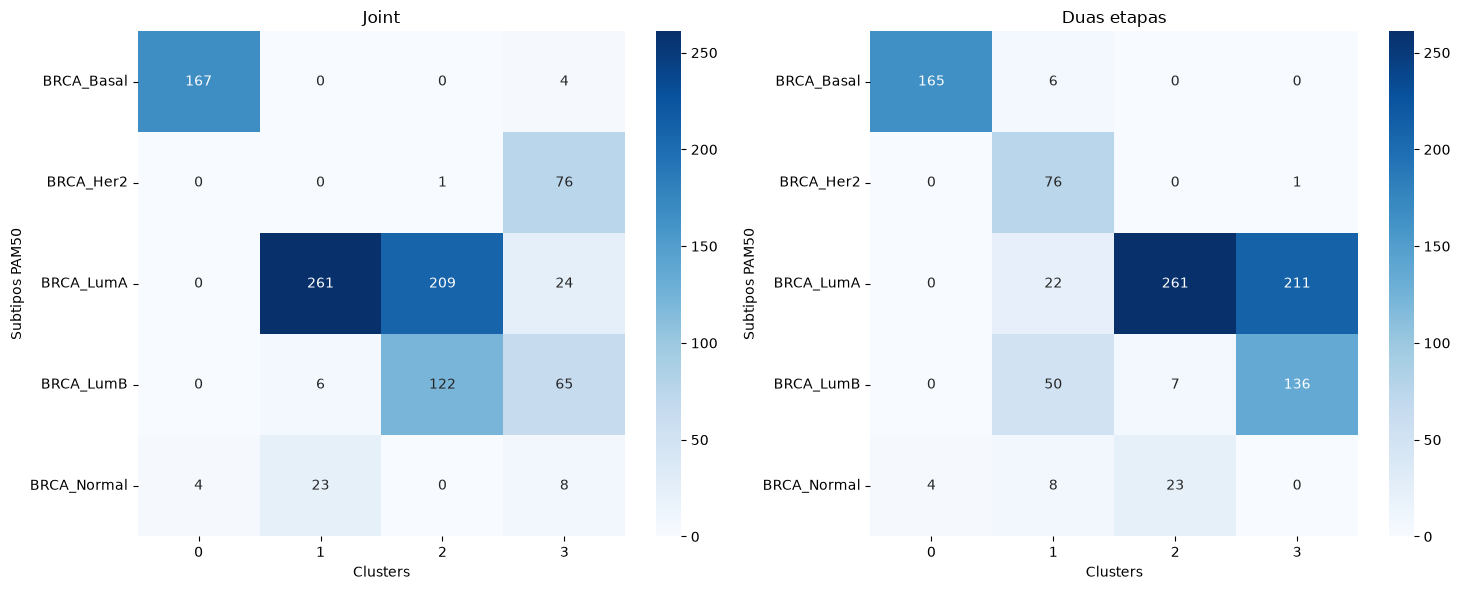

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(
    contingency_joint,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("Joint")
axes[0].set_xlabel("Clusters")
axes[0].set_ylabel("Subtipos PAM50")

sns.heatmap(
    contingency_decoupled,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[1]
)

axes[1].set_title("Duas etapas")
axes[1].set_xlabel("Clusters")
axes[1].set_ylabel("Subtipos PAM50")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "contingency_vst_mad_3000_v2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Plot dos Embeddings

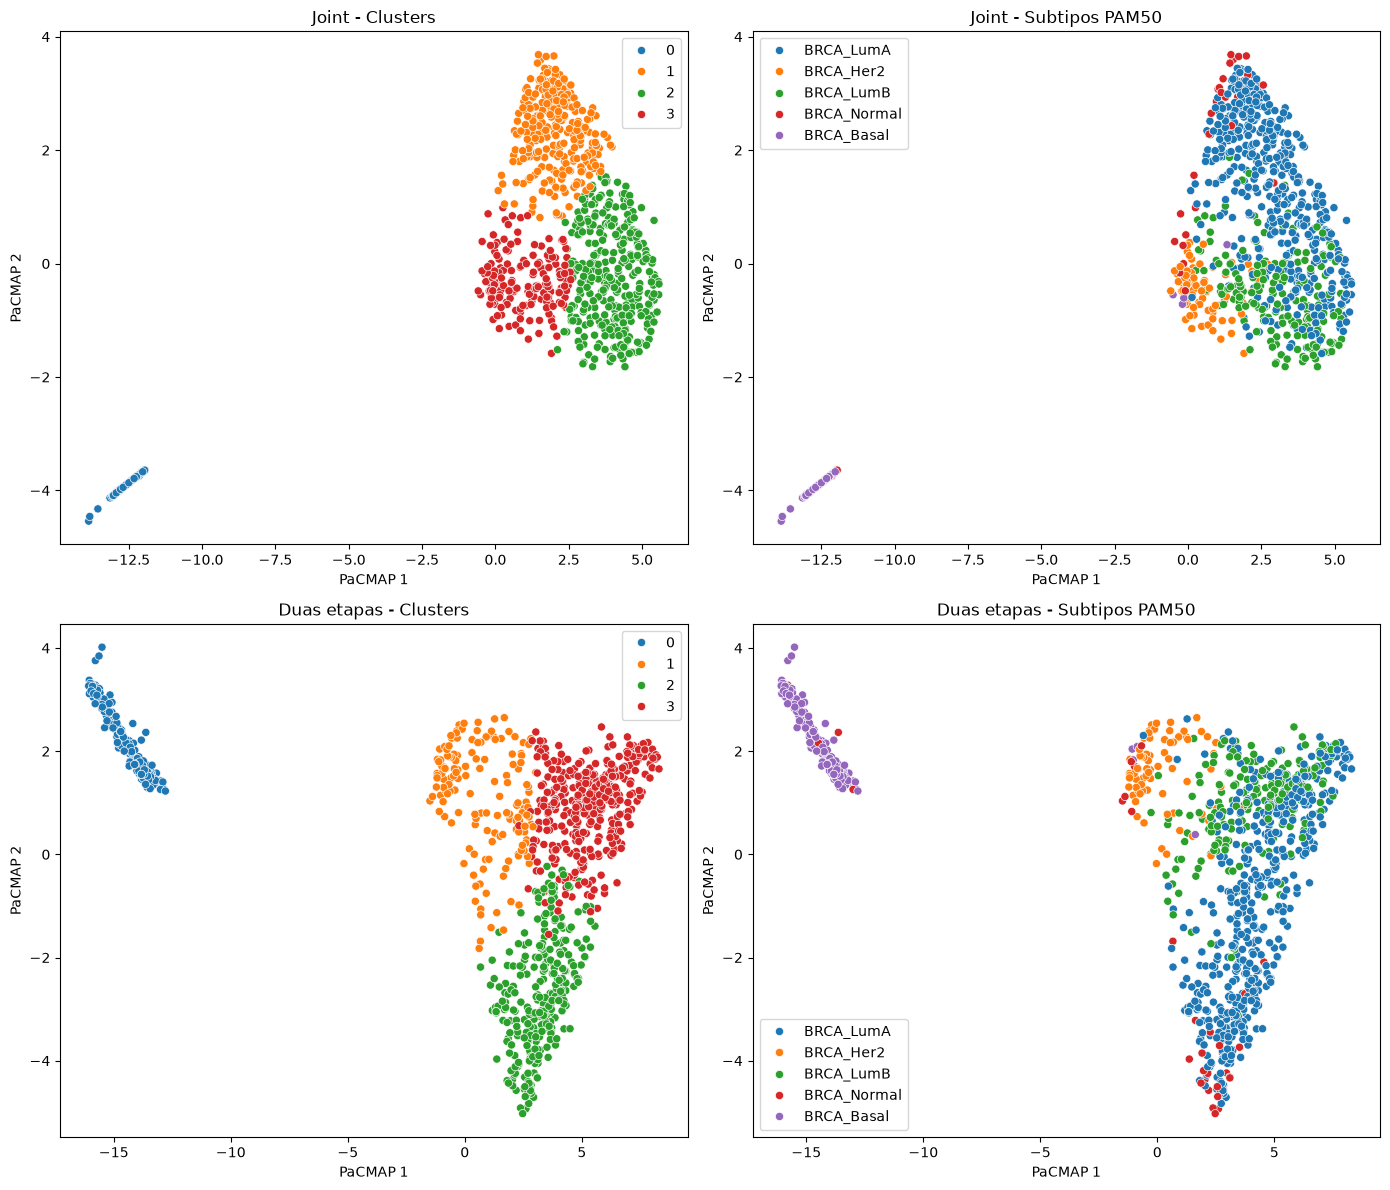

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Joint - clusters
sns.scatterplot(
    x=Z_joint[:, 0],
    y=Z_joint[:, 1],
    hue=labels_joint,
    palette="tab10",
    s=35,
    ax=axes[0, 0],
    legend="full"
)

axes[0, 0].set_title("Joint - Clusters")
axes[0, 0].set_xlabel("PaCMAP 1")
axes[0, 0].set_ylabel("PaCMAP 2")

# Joint - subtipos
sns.scatterplot(
    x=Z_joint[:, 0],
    y=Z_joint[:, 1],
    hue=y_true,
    palette="tab10",
    s=35,
    ax=axes[0, 1],
    legend="full"
)

axes[0, 1].set_title("Joint - Subtipos PAM50")
axes[0, 1].set_xlabel("PaCMAP 1")
axes[0, 1].set_ylabel("PaCMAP 2")

# Duas etapas - clusters
sns.scatterplot(
    x=Z_decoupled[:, 0],
    y=Z_decoupled[:, 1],
    hue=labels_decoupled,
    palette="tab10",
    s=35,
    ax=axes[1, 0],
    legend="full"
)

axes[1, 0].set_title("Duas etapas - Clusters")
axes[1, 0].set_xlabel("PaCMAP 1")
axes[1, 0].set_ylabel("PaCMAP 2")

# Duas etapas - subtipos
sns.scatterplot(
    x=Z_decoupled[:, 0],
    y=Z_decoupled[:, 1],
    hue=y_true,
    palette="tab10",
    s=35,
    ax=axes[1, 1],
    legend="full"
)

axes[1, 1].set_title("Duas etapas - Subtipos PAM50")
axes[1, 1].set_xlabel("PaCMAP 1")
axes[1, 1].set_ylabel("PaCMAP 2")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "embeddings_vst_mad_3000_v2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Comparação das Métricas

In [39]:
# Recupera as métricas dos melhores ensaios Joint
best_trial_joint = study_joint.best_trial

results_comparison = pd.DataFrame({
    "Estratégia": [
        "Joint",
        "Duas etapas"
    ],

    "Qlocal": [
        best_trial_joint.user_attrs["Qlocal"],
        q_local_decoupled
    ],

    "AUC QNN": [
        best_trial_joint.user_attrs["AUC_QNN"],
        auc_qnn_decoupled
    ],

    "Silhouette": [
        best_trial_joint.user_attrs["Silhouette"],
        sil_decoupled
    ],

    "Calinski-Harabasz": [
        best_trial_joint.user_attrs["Calinski_Harabasz"],
        ch_decoupled
    ],

    "ARI": [
        adjusted_rand_score(y_true, labels_joint),
        ari_decoupled
    ],

    "Número de clusters": [
        len(np.unique(labels_joint)),
        len(np.unique(labels_decoupled))
    ]
})

display(results_comparison.round(4))

results_comparison.to_csv(
    METRICS_DIR / "comparison_vst_mad_3000_v2.csv",
    index=False
)

results_comparison.to_excel(
    METRICS_DIR / "comparison_vst_mad_3000_v2.xlsx",
    index=False
)

,Estratégia,Qlocal,AUC QNN,Silhouette,Calinski-Harabasz,ARI,Número de clusters
0,Joint,0.4134,0.7537,0.8725,12733.0132,0.3969,4
1,Duas etapas,0.4403,0.7530,0.7986,5471.1273,0.3344,4


## Comparação dos parâmetros

In [41]:
params_comparison = pd.DataFrame([
    {
        "Estratégia": "Joint",
        **best_params_joint
    },
    {
        "Estratégia": "Duas etapas",
        **{
            "n_neighbors": best_params_pacmap["n_neighbors"],
            "MN_ratio": best_params_pacmap["MN_ratio"],
            "FP_ratio": best_params_pacmap["FP_ratio"],
            "n_components": best_params_pacmap["n_components"],
            "gmm_n_components": best_params_gmm["n_components"],
            "covariance_type": best_params_gmm["covariance_type"],
            "n_init": best_params_gmm["n_init"]
        }
    }
])

display(params_comparison)

params_comparison.to_csv(
    METRICS_DIR / "hyperparameters_vst_mad_3000_v2.csv",
    index=False
)

,Estratégia,n_neighbors,MN_ratio,FP_ratio,n_components,gmm_n_components,covariance_type,n_init
0,Joint,94,0.219072,1.457864,7,2,diag,9
1,Duas etapas,26,1.838967,2.811595,8,2,full,10
